In [43]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
data = pd.read_csv('fma_dataset_filtered.csv')
data.head()


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


In [45]:
data.shape

(2406, 524)

In [46]:
data.describe()

,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
count,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,...,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000
mean,27246.670823,0.063542,-0.082459,0.024900,-0.073564,0.010460,-0.044657,-0.062988,-0.014984,-0.065439,...,0.368378,0.050561,0.041361,0.002678,3.428497,0.036722,242.634248,114.593813,0.490342,0.349536
std,25169.208602,1.891557,1.106436,1.501832,1.098007,1.573417,1.150381,1.240372,1.421700,1.364783,...,0.164931,0.031612,0.029588,0.005184,2.852553,0.024209,238.691886,37.143449,0.186391,0.252201
min,2.000000,-1.713556,-1.651053,-1.793530,-1.601526,-1.745835,-1.558694,-1.558443,-1.690922,-1.680693,...,0.051270,0.003505,0.000000,0.000000,-1.062790,0.004279,31.000000,19.659000,0.053491,0.000077
25%,11788.250000,-0.693621,-0.689587,-0.697414,-0.699416,-0.713293,-0.695228,-0.694451,-0.683760,-0.708446,...,0.252686,0.031478,0.024414,0.000000,1.726614,0.017921,150.000000,89.524750,0.356900,0.126627
50%,19076.500000,-0.285531,-0.332003,-0.314715,-0.322115,-0.308662,-0.300797,-0.321902,-0.304667,-0.342531,...,0.369141,0.045578,0.036133,0.000000,2.648856,0.030944,196.000000,105.010000,0.477879,0.314594
75%,33714.750000,0.285472,0.212239,0.272046,0.242089,0.287923,0.245239,0.214084,0.213251,0.201312,...,0.450684,0.063127,0.051270,0.003418,4.272882,0.051037,256.000000,137.849000,0.625101,0.531563
max,124722.000000,42.851593,14.327950,20.394966,19.266939,43.405674,17.028032,30.522015,30.898539,35.876045,...,0.996094,0.488016,0.491699,0.074707,29.338261,0.210072,2926.000000,241.277000,0.961871,0.999537


In [47]:
x = data.drop(columns = ['genre', 'track_id'])
scaler = StandardScaler().set_output(transform="pandas")
x = scaler.fit_transform(x) # если не применить, PCA работать не будет, объясненная дисперсия будет равна единице
y = data.genre
x

,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,chroma_cens_kurtosis_10,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
0,3.763350,4.802694,0.149462,1.294600,0.935749,0.500832,1.245515,1.904060,0.683259,1.111415,...,0.552435,1.109582,1.011679,-0.516662,-0.469370,1.021568,-0.312745,1.382178,0.995706,1.130052
1,0.965237,0.762063,0.213381,2.157781,1.044804,0.097596,1.152987,0.752128,0.127183,0.544318,...,0.593891,1.076329,0.764091,-0.516662,-0.600209,1.347216,-0.023610,0.332919,0.205530,1.855755
2,0.245363,0.004344,-0.202802,0.691804,1.225047,0.804679,-0.693649,-0.641793,0.536501,0.873686,...,0.040158,0.080782,0.004823,-0.516662,-0.433103,0.336255,-0.153511,-0.385984,1.369578,1.395743
3,0.452051,0.683965,0.368239,1.234021,0.586925,0.106799,1.017803,-0.112733,0.726215,1.187818,...,0.309621,0.436910,0.318434,-0.516662,-0.568869,0.739583,-0.149321,-0.008181,0.122864,0.836310
4,-0.044634,0.465364,0.204045,0.822944,1.662418,1.782664,0.782744,0.536916,1.191516,2.073156,...,-0.649788,0.639106,0.863126,-0.328258,-0.932458,-0.277027,0.223622,2.218004,-1.231169,1.021348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,-0.285196,-0.617568,-0.368964,-0.300093,0.847396,-0.122511,-0.313397,-0.335577,-0.609698,0.044993,...,0.904810,0.821686,0.483492,-0.516662,-0.477678,1.335135,-0.170273,-0.497898,1.054365,1.982062
2402,0.050419,-0.117075,0.187725,-0.318805,-0.789800,-0.987789,-0.501947,0.417300,-0.206877,-0.896723,...,0.818937,0.591299,-0.110718,-0.516662,-0.445645,1.832253,-0.174463,-0.493644,0.682541,1.503210
2403,-0.393821,0.581044,-0.624613,-0.236991,0.158994,1.040032,0.455482,-0.780155,-0.595748,-0.686821,...,0.718259,0.472345,0.351445,-0.139854,-0.346642,0.817715,-0.258270,-0.530724,0.870078,1.221353
2404,-0.502598,0.904257,0.699202,-0.655471,-0.504936,-0.763956,-0.209942,0.708346,0.308497,0.564111,...,2.160334,0.588799,0.070846,-0.516662,0.306154,2.300162,-0.430076,1.527779,-0.310816,1.645748


In [48]:
y

0       Hip-Hop
1       Hip-Hop
2       Hip-Hop
3       Hip-Hop
4          Folk
         ...   
2401    Hip-Hop
2402    Hip-Hop
2403    Hip-Hop
2404    Hip-Hop
2405    Hip-Hop
Name: genre, Length: 2406, dtype: object

In [49]:
pca = PCA(n_components=2).fit_transform(x)
pca = pd.DataFrame(pca, columns=['pc_1', 'pc_2'])
pca.head()

,pc_1,pc_2
0,-7.685346,-0.759412
1,-10.188713,1.699822
2,-6.898331,1.583597
3,-8.947769,3.961596
4,-5.512512,-4.259609


In [50]:
pca.shape

(2406, 2)

<Axes: xlabel='pc_1', ylabel='pc_2'>

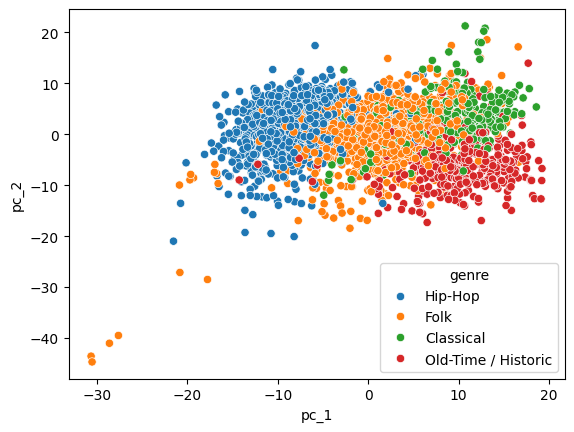

In [51]:
sns.scatterplot(x ='pc_1', y = 'pc_2', data=pca, hue=y) # Ого, получилось

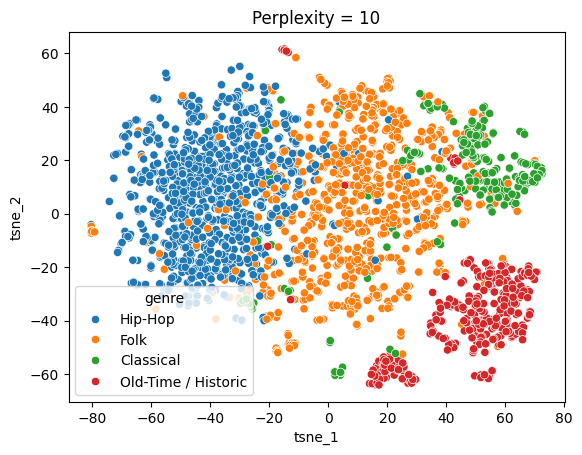

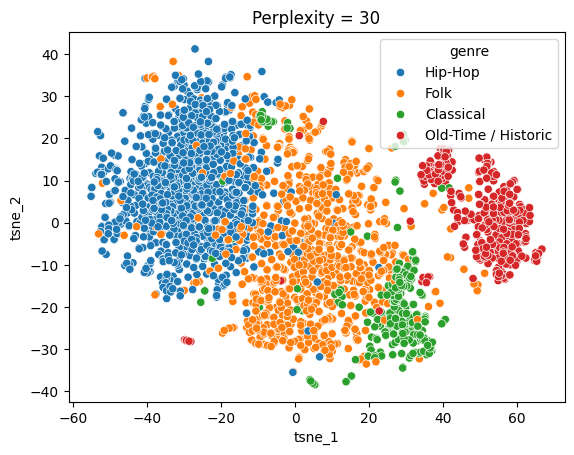

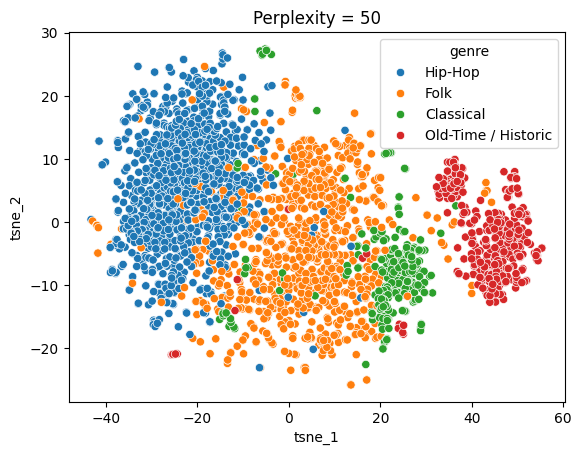

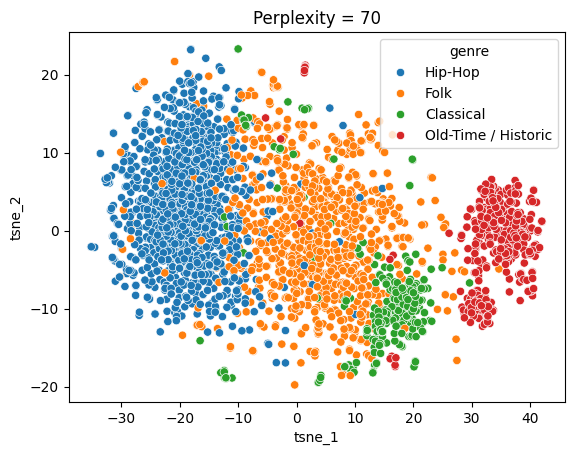

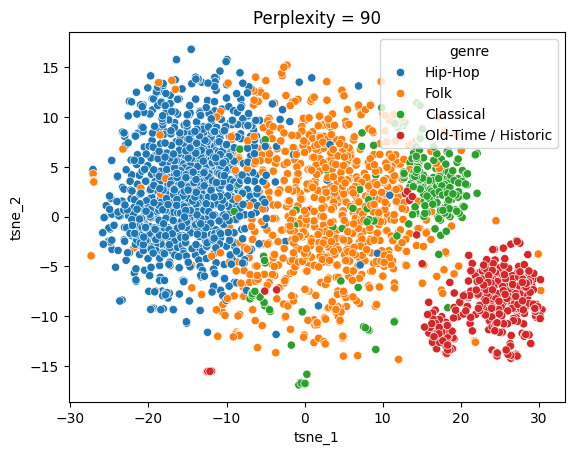

In [52]:
for i in range(1, 11, 2):
    tsne = TSNE(perplexity=i*10).fit_transform(x)
    tsne = pd.DataFrame(tsne, columns=['tsne_1', 'tsne_2'])
    sns.scatterplot(x = 'tsne_1', y = 'tsne_2', data=tsne, hue=y)
    plt.title('Perplexity = {0}'.format(i*10))
    plt.show()

In [53]:
from sklearn import decomposition
pca = decomposition.PCA(n_components=x.shape[1])
pca.fit(x)

,n_components,522
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


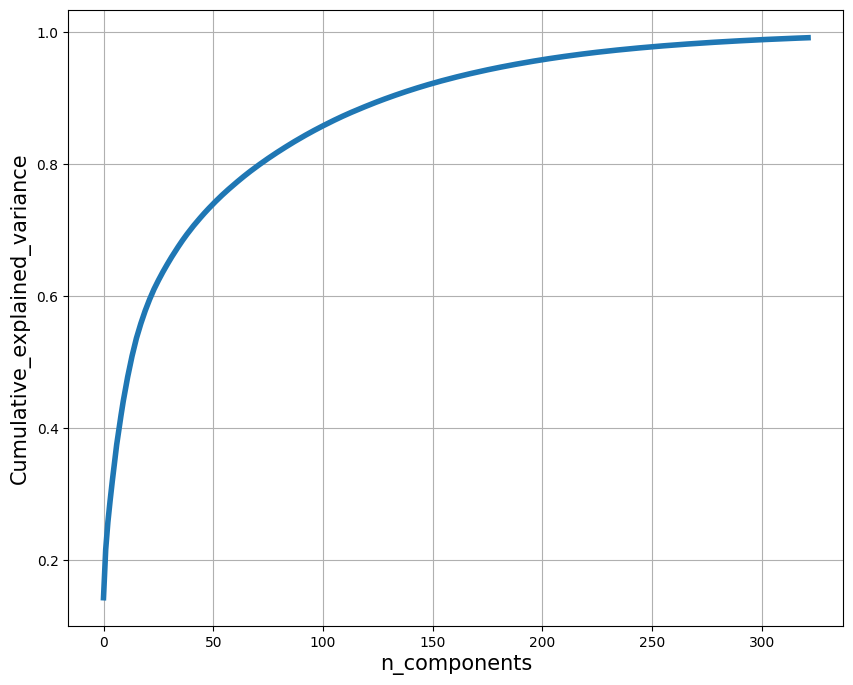

2D -  0.21640999012083542
200D -  0.9580414471050712


In [54]:
pca.n_components = 322
pca_data = pca.fit_transform(x)

percentage_var_explained = pca.explained_variance_ratio_
cum_var_explained = np.cumsum(percentage_var_explained)

plt.figure(figsize=(10, 8))
plt.plot(cum_var_explained, linewidth=4)
plt.axis('tight')
plt.grid()
plt.xlabel('n_components', size=15)
plt.ylabel('Cumulative_explained_variance', size=15)
plt.show()

print("2D - ", cum_var_explained[1]) # Значение было 2, значит было 3 компоненты, и это было 3D
print("200D - ",cum_var_explained[199]) # метод хорошо работает, при повышении измерения повышается объяснение дисперсии

In [55]:
print(cum_var_explained[321])

0.991869291852788


In [56]:

km = KMeans(n_clusters=4, n_init=1, max_iter=10, random_state=42, init='random') #n_clusters - количество жанров
km.fit(x)
# А как это лучше визуализировать? Я боролся с этим долго, брал за пример вашу работу с Kmeans, но там визуализация идет по осям x и y, которые там очевидны. А тут? Или с PCA и t-sne было достаточно?

,n_clusters,4
,init,'random'
,n_init,1
,max_iter,10
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [57]:
from sklearn.metrics import silhouette_score, rand_score

In [58]:
labels = km.fit_predict(x)
print('silhouette_score - ', silhouette_score(x, labels)) #Почему так мало? 500+ мерное пространство и должно занижать оценку, rand_score показывает неплохой результат
print('rand_score - ', rand_score(y, labels))

silhouette_score -  0.0679418242426634
rand_score -  0.7625278453208628


In [59]:
from sklearn.metrics import adjusted_rand_score

In [60]:
print("adjusted_rand_score - ", adjusted_rand_score(y, labels))

adjusted_rand_score -  0.4409750955416615


In [61]:
print(y.nunique())

4


In [62]:
for i in range(2, 7):
    km = KMeans(n_clusters=i, n_init=1, max_iter=10, random_state=42, init='random') #n_clusters - количество жанров(вообще их 4)
    km.fit(x)
    labels = km.fit_predict(x)
    print('n_clusters = ', i, ' silhouette_score - ', silhouette_score(x, labels), 'rand_score - ', rand_score(y, labels))

n_clusters =  2  silhouette_score -  0.10957605145660479 rand_score -  0.6803386544034923
n_clusters =  3  silhouette_score -  0.080065509735892 rand_score -  0.676821114227598
n_clusters =  4  silhouette_score -  0.0679418242426634 rand_score -  0.7625278453208628
n_clusters =  5  silhouette_score -  0.03435579381217055 rand_score -  0.7775671700858733
n_clusters =  6  silhouette_score -  0.03690910047593285 rand_score -  0.7595460413415526


# Ответы и вывод
## 6.1 Они отражают примерное распределение жанров. PCA - быстрый метод сжатия данных, с сохранением общей структуры, t-SNE для 2D или 3D визуализации. Мне больше понравился t-SNE, он более наглядный и удобнее для восприятия

## 6.2 2D - 0.21640999012083523 если быть совсем точным и помнить, что индексация идет с нуля, т.е. такой процент исходных признаков сохраняет компонента

## 6.3 Ну конечно rand_score лучше, потому что у меня на нем лучше показатель:) rand_score показывает насколько правильно Kmeans сгруппировал объекты, Silhouette на геометрию, т.к. на каждый объект по 500 признаков, и Silhouette из-за этого занижается(значит ли это, что его нельзя использовать при большом количестве признаков?)

## 6.4 Ответ исходит из пункта 6.3. Рекомендательная система предлагала бы песни одного и того же класса(приоритет не геометрическое расстояние между объектами, т.к. оно здесь не работает, а соответствие классу)

## 6.5 В зависимости от задачи:) Рекомендательная система могла бы и предлагать песни по длине, я же пошел через жанр песней.